# Commuting zones: a live LLM specification search

This case predicts the **male income life-expectancy gap** across US commuting
zones — race-adjusted expected age at death for top-quartile men minus the same
quantity for bottom-quartile men — and holds out entire states for a one-time
test. A language model served through NVIDIA NIM (NVIDIA inference microservice, `z-ai/glm-5.3`) chooses public
`SearchSession` actions through `LLMJudge` and `session.drive`. The page
reads a frozen transcript of the recorded run and does not call the provider.

The sibling page [](cz_agent_search.ipynb) uses the same session API on absolute
Q1 male life expectancy, but its judgments are hand-authored: **no LLM ran
there**. Here the frozen transcript records the language model's chosen actions. Both studies report ecological predictive associations, not intervention
effects {cite:p}`chetty2016inequality`.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | prediction of male Q4−Q1 life-expectancy gaps for zones in states absent from fitting |
| **Response** | `le_gap_M = le_raceadj_q4_M − le_raceadj_q1_M`, race-adjusted years |
| **Estimand** | mean squared prediction error on held-out-state zones, in years² |
| **Units** | years of expected age-at-death difference between income quartiles |
| **Sampling unit** | one commuting zone; zones within a state may be dependent |
| **Dependence** | state clustering; grouped folds keep whole states together |
| **Split unit** | entire states; one of five state groups is reserved for final testing; five folds of the remaining states choose specifications and `mstop` |
| **Tuning** | boosting iterations chosen by training-state cross-validation after adoption |
| **Uncertainty** | paired fold standard errors on exploratory training comparisons; one held-out state group supplies the final score |
| **Claim type** | predictive ecological association for area-level inequality, not causal |
:::

## Male income life-expectancy gap

Chetty and coauthors found large geographic variation in longevity for low-income
residents, strong correlations with smoking, obesity and exercise, and little
association with Gini indices (measures of income inequality), Medicare access measures or labour-market
conditions. Predicting the *gap* between top and bottom quartiles asks whether
those behavioural patterns also organise inequality across places. The starting model includes inequality proxies and a linear longitude term;
the search tests whether they improve prediction of this gap.


In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")

RECORD = Path("bench_cz_llm_agent_search.json")
record = json.loads(RECORD.read_text())
assert record.get("status") in {"ok", "incomplete", "pending_live_run"}, record.get("status")

In [2]:
# Reconstruct the frozen run's state split before displaying its record.
raw = mb.datasets.hip_cz(output="polars").with_columns(
    (pl.col("le_raceadj_q4_M") - pl.col("le_raceadj_q1_M")).alias("le_gap_M")
)
columns = [
    "le_gap_M", "stateabbrv", "cur_smoke_q1", "bmi_obese_q1", "exercise_any_q1",
    "gini99", "reimb_penroll_adj10", "scap_ski90pcm", "cs_educ_ba",
    "unemp_rate", "lon",
]
frame = raw.select(columns).drop_nulls()
assignment = np.asarray(mb.grouped_folds(
    np.asarray(frame["stateabbrv"].to_list(), dtype=object), B=5, seed=2016))
train = frame.filter(pl.Series(assignment[:, 0] != 0))
test = frame.filter(pl.Series(assignment[:, 0] == 0))
print(f"Training: {train.height} zones in {train['stateabbrv'].n_unique()} states")
print(f"Test: {test.height} zones in {test['stateabbrv'].n_unique()} states")
print(f"Frozen status: {record['status']}; model: {record.get('model')}")
print(f"Holdout summary: {record.get('holdout')}")

model_id = record.get("model")
provider_status = (record.get("provider_calls") or [{}])[0].get("status")
drive_status = record.get("drive_status")
holdout_mse = (record.get("holdout") or {}).get("score")
print(f"Drive: {drive_status}")



Training: 468 zones in 39 states
Test: 118 zones in 10 states
Frozen status: ok; model: z-ai/glm-5.3
Holdout summary: {'score': 2.284181947633402, 'score_name': 'mse', 'n_test': 118, 'task': 'one-time untouched-test evaluation'}
Drive: compact_judge_ok,llm_adopt:drop_gini


## Frozen provider-backed search

The live driver `tools/cz_llm_agent/run_live_search.py` opens a `SearchSession`
on training states only, records analyst hypotheses, sets a starting
formula with all listed predictors (including a linear `bols(lon)` term), and hands control
to `LLMJudge` via `session.drive`. Provider prompts, reply hashes and token usage
are stored with the action history. Test responses are read once, after `freeze` fixes every choice in the fitted model.


In [3]:
transcript = pl.DataFrame([
    {
        "action": row["action"],
        "status": row["status"],
        "fit_charges": row["fit_charges"],
        "evidence": row["evidence_id"][:10],
        "note": (row.get("summary") or {}).get("chosen_action")
                or str((row.get("summary") or {}).get("reasoning", ""))[:80]
                or str((row.get("summary") or {}).get("spec", ""))[:80]
                or "",
    }
    for row in record.get("transcript", [])
])
display(table(
    transcript,
    title="Provider-backed action record",
    subtitle="Judge decisions, measured comparisons and one final test evaluation",
    stub="action", stubhead="Operation",
    notes=("Evidence prefixes identify full records in the frozen JSON.",
           "Judge rows carry provider hashes; compare/adopt rows are measured on training-state folds."),
))
print(f"Provider calls: {len(record.get('provider_calls', []))}")
for call in record.get("provider_calls", [])[:3]:
    print(f"  {call.get('status')}: tokens={call.get('usage')}")


GT(_tbl_data=shape: (11, 5)
┌────────────────┬────────────────┬─────────────┬────────────┬─────────────────────────────────┐
│ action         ┆ status         ┆ fit_charges ┆ evidence   ┆ note                            │
│ ---            ┆ ---            ┆ ---         ┆ ---        ┆ ---                             │
│ str            ┆ str            ┆ i64         ┆ str        ┆ str                             │
╞════════════════╪════════════════╪═════════════╪════════════╪═════════════════════════════════╡
│ hypothesis     ┆ screening_only ┆ 0           ┆ c99d597083 ┆                                 │
│ hypothesis     ┆ screening_only ┆ 0           ┆ ec8e3f5603 ┆                                 │
│ hypothesis     ┆ screening_only ┆ 0           ┆ 9f33ea95a6 ┆                                 │
│ hypothesis     ┆ screening_only ┆ 0           ┆ 702c5ecfd0 ┆                                 │
│ set_spec       ┆ unmeasured     ┆ 0           ┆ ab17e7e7b6 ┆ bols(cur_smoke_q1) + bols(bmi_… │
│ …              ┆ …              ┆ …           ┆ …          ┆ …                               │
│ compare        ┆ measured       ┆ 20          ┆ 466a7bed68 ┆                                 │
│ adopt          ┆ unmeasured     ┆ 0           ┆ c10b054e37 ┆ bols(cur_smoke_q1) + bols(bmi_… │
│ tune           ┆ measured       ┆ 6           ┆ 536912010b ┆                                 │
│ freeze         ┆ unmeasured     ┆ 0           ┆ 23180ef666 ┆ bols(cur_smoke_q1) + bols(bmi_… │
│ final_evaluate ┆ measured       ┆ 0           ┆ 916c895b9b ┆                                 │
└────────────────┴────────────────┴─────────────┴────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10ba8f5f0>, _boxhead=Boxhead([ColInfo(var='action', type=<ColInfoTypeEnum.stub: 2>, column_label='action', column_align='left', column_width=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None), ColInfo(var='fit_charges', type=<ColInfoTypeEnum.default: 1>, column_label='fit_charges', column_align='right', column_width=None), ColInfo(var='evidence', type=<ColInfoTypeEnum.default: 1>, column_label='evidence', column_align='left', column_width=None), ColInfo(var='note', type=<ColInfoTypeEnum.default: 1>, column_label='note', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dd7f680>, _spanners=Spanners([]), _heading=Heading(title='Provider-backed action record', subtitle='Judge decisions, measured comparisons and one final test evaluation', preheader=None), _stubhead='Operation', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10dc90530>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b9a73b0>, _source_notes=['Evidence prefixes identify full records in the frozen JSON.', 'Judge rows carry provider hashes; compare/adopt rows are measured on training-state folds.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10b723ef0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10b982c00>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', '

Provider calls: 1
  received: tokens={'prompt_tokens': 1002, 'completion_tokens': 904, 'total_tokens': 1906, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 654, 'rejected_prediction_tokens': None}}


## Initial specification and recorded hypotheses

The session begins with linear main effects of smoking, obesity, exercise, Gini,
Medicare reimbursement, social capital, college share, unemployment and longitude,
plus a random state effect locked against removal. Hypotheses state what would
count against each interpretation before any candidate is scored.


In [4]:
hyp = pl.DataFrame([
    {"variable": h.get("variable"), "role": h.get("role"),
     "statement": str(h.get("statement", ""))[:90]}
    for h in record.get("hypotheses", [])
])
display(table(
    hyp, title="Analyst hypotheses recorded before search scores",
    subtitle="Roles and falsifiers enter the ledger; they do not change the fit",
    stub="variable", stubhead="Variable",
))
print("Initial specification:")
print(record.get("initial_spec"))
print("Accepted specification:")
print(record.get("final_spec"))
print(f"Tuned mstop: {record.get('mstop')}")


GT(_tbl_data=shape: (4, 3)
┌─────────────────┬─────────────────────────────────┬─────────────────────────────────┐
│ variable        ┆ role                            ┆ statement                       │
│ ---             ┆ ---                             ┆ ---                             │
│ str             ┆ str                             ┆ str                             │
╞═════════════════╪═════════════════════════════════╪═════════════════════════════════╡
│ cur_smoke_q1    ┆ health-behaviour pathway (gap … ┆ Higher Q1 smoking should predi… │
│ gini99          ┆ income-inequality candidate, l… ┆ Area Gini may not add predicti… │
│ lon             ┆ nonsense linear geography bait  ┆ Longitude as a linear effect i… │
│ exercise_any_q1 ┆ health-behaviour pathway (gap … ┆ Higher Q1 exercise rates shoul… │
└─────────────────┴─────────────────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10b983200>, _boxhead=Boxhead([ColInfo(var='variable', type=<ColInfoTypeEnum.stub: 2>, column_label='variable', column_align='left', column_width=None), ColInfo(var='role', type=<ColInfoTypeEnum.default: 1>, column_label='role', column_align='left', column_width=None), ColInfo(var='statement', type=<ColInfoTypeEnum.default: 1>, column_label='statement', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dd7e6f0>, _spanners=Spanners([]), _heading=Heading(title='Analyst hypotheses recorded before search scores', subtitle='Roles and falsifiers enter the ledger; they do not change the fit', preheader=None), _stubhead='Variable', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b9a73b0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b722d50>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10dd7fe60>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10dd7f7a0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=Tru

Initial specification:
bols(cur_smoke_q1) + bols(bmi_obese_q1) + bols(exercise_any_q1) + bols(gini99) + bols(reimb_penroll_adj10) + bols(scap_ski90pcm) + bols(cs_educ_ba) + bols(unemp_rate) + bols(lon) + brandom(stateabbrv)
Accepted specification:
bols(cur_smoke_q1) + bols(bmi_obese_q1) + bols(exercise_any_q1) + bols(reimb_penroll_adj10) + bols(scap_ski90pcm) + bols(cs_educ_ba) + bols(unemp_rate) + bols(lon) + brandom(stateabbrv)
Tuned mstop: 88


## Measured alternatives

After tuning the initial specification, the session compares three complete formulas on the
same state folds: drop linear longitude, drop Gini, and replace smoking with an
increasing monotone constraint. Negative changes favour the candidate. Removals
with a change within two paired standard errors are eligible under the session's
descriptive preference for a smaller model.


In [5]:
compare = next(
    (row for row in record.get("transcript", [])
     if row["action"] == "compare" and row["status"] == "measured"),
    None,
)
if compare is None:
    print("No measured comparison in the frozen transcript.")
else:
    rows = pl.DataFrame([
        {"candidate": r["specification"],
         "mse": r["out-of-fold risk"],
         "change": r["change"],
         "se": r["change se"]}
        for r in compare["summary"]["rows"]
    ])
    display(table(
        rows,
        title="Kitchen-sink alternatives on training states",
        subtitle="MSE and paired changes in years²; lower is better",
        stub="candidate", stubhead="Candidate", better={"mse": "min"},
        notes=("Change = candidate MSE − kitchen-sink MSE.",
               "SE uses five shared state folds and is unadjusted for searching these alternatives.",
               "These are predictive checks, not tests of interventions."),
    ))


GT(_tbl_data=shape: (4, 4)
┌────────────┬──────────┬──────────┬──────────┐
│ candidate  ┆ mse      ┆ change   ┆ se       │
│ ---        ┆ ---      ┆ ---      ┆ ---      │
│ str        ┆ f64      ┆ f64      ┆ f64      │
╞════════════╪══════════╪══════════╪══════════╡
│ current    ┆ 1.932937 ┆ 0.0      ┆ 0.0      │
│ drop_lon   ┆ 1.95274  ┆ 0.019803 ┆ 0.00873  │
│ drop_gini  ┆ 1.932937 ┆ 0.0      ┆ 0.0      │
│ mono_smoke ┆ 1.938504 ┆ 0.005567 ┆ 0.011585 │
└────────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10b722d50>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='mse', column_align='right', column_width=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='change', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dd7e6f0>, _spanners=Spanners([]), _heading=Heading(title='Kitchen-sink alternatives on training states', subtitle='MSE and paired changes in years²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b980950>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b983110>, _source_notes=['Change = candidate MSE − kitchen-sink MSE.', 'SE uses five shared state folds and is unadjusted for searching these alternatives.', 'These are predictive checks, not tests of interventions.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10dd7fef0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10b36b9e0>, <great_tables._gt_data.FormatInfo object at 0x10b722bd0>, <great_tables._gt_data.FormatInfo object at 0x10b983170>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10dd7c230>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value

## Live judgment

`LLMJudge` receives a compact digest, a short summary of the measured rows, rather than the full session state and returns one JSON action. In the frozen run the model is
{eval}`model_id`; provider status is {eval}`provider_status`. The chosen adoption
appears in `drive_status` as `llm_adopt:drop_gini`: Gini's paired change is
essentially zero, matching Chetty's finding that income-inequality indices do not
organise low-income longevity across places. Dropping longitude does **not**
clear the rule — the linear longitude term improves held-out error slightly as a
crude spatial proxy, so the adopted formula retains it. The increasing
smoking constraint does not improve fold MSE enough to adopt.


## Accepted specification

The adopted formula drops Gini and retains the behavioural terms, Medicare
reimbursement, social capital, education, unemployment and linear longitude.
It is retuned on training states before freeze. The holdout MSE comes from the
one-shot `final_evaluate` on untouched test states.


In [6]:
spec = record.get("final_spec")
holdout = record.get("holdout") or {}
holdout_mse = holdout.get("score")
print(f"Held-out MSE (years²): {holdout_mse}")
print(f"Test zones: {holdout.get('n_test')}")

if spec and record.get("status") == "ok":
    fit = mb.gamboost(
        f"le_gap_M ~ {spec}", train,
        family=mb.Gaussian(),
        control=mb.boost_control(int(record.get("mstop") or 100), 0.3),
    )
else:
    fit = None
    print("No accepted live fit to refit; showing transcript only.")


Held-out MSE (years²): 2.284181947633402
Test zones: 118


## Conditional smoking profile

Each point varies Q1 smoking between its fifth and 95th training percentiles,
holds other covariates at training medians, and predicts an average new state.
A rising profile is consistent with smoking widening the income LE gap in this
fitted model. It is not the effect of making individuals quit.


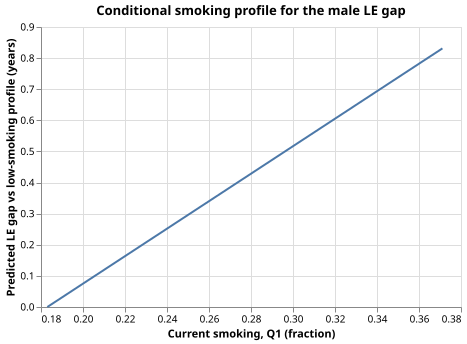

In [7]:
if fit is not None:
    # Hold other covariates at training medians to isolate the smoking profile.
    median = {name: float(train[name].median()) for name in columns
              if name not in ("le_gap_M", "stateabbrv")}
    smoke = np.linspace(train["cur_smoke_q1"].quantile(0.05),
                        train["cur_smoke_q1"].quantile(0.95), 60)
    rows = {name: np.repeat(value, len(smoke)) for name, value in median.items()}
    rows["stateabbrv"] = np.repeat("new state", len(smoke))
    rows["cur_smoke_q1"] = smoke
    pred = np.asarray(fit.predict(rows, type="response", unseen_levels="average"))
    profile = pl.DataFrame({
        "smoking_share": smoke,
        "relative_gap_years": pred - pred[0],
    })

    chart = (
        alt.Chart(profile).mark_line()
        .encode(
            x=alt.X("smoking_share:Q", title="Current smoking, Q1 (fraction)"),
            y=alt.Y("relative_gap_years:Q",
                    title="Predicted LE gap vs low-smoking profile (years)"),
        )
        .properties(title="Conditional smoking profile for the male LE gap",
                    width=420, height=280)
    )
    display(chart)
else:
    print("Profile skipped until a live accepted specification is frozen.")


## Comparison with the analyst-directed CZ search

| | [](cz_agent_search.ipynb) | This page |
|---|---|---|
| Response | Absolute Q1 male LE | Male Q4−Q1 LE gap |
| Judgment source | Hand-written notebook cells | Live `LLMJudge` / `session.drive` |
| Provider | None | NIM `z-ai/glm-5.3` with hashed prompts |
| Reproducibility | Deterministic calls in source | Frozen JSON transcript |
| Claim | Predictive association | Predictive association |

The holdout MSE here is not numerically comparable to the absolute-LE score of
about 1.36 years² on the sibling page: the responses differ. This run demonstrates an LLM choosing session actions, comparing terms and
constraints, and freezing a model before testing. Its score cannot establish
that the gap is easier to predict than absolute life expectancy.

## Limits

One state split does not characterise variability across other training samples.
Judge proposals remain proposals until a measured comparison accepts them.
Area-level behavioural correlates can proxy many shared causes; nothing here
identifies the effect of changing smoking, exercise or Gini in a zone.
